<h1>Stroke Prediction Analysis</h1>


<h3>1.Import Libraries</h3>

In [107]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

<h3>2.Load data</h3>

In [108]:
data =pd.read_csv('healthcare-dataset-stroke-data.csv')
print("Shape:",data.shape)
data.head()


Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


<h3>3.Inspect the data</h3>

In [109]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [110]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6


<h3>4.Data Cleaning(missing values,duplicate values,only one different value)</h3>

In [111]:
#Missing values
print(data.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [112]:
#Bmi has missing values, we will fill them with the median value of the bmi column
data['bmi']=data['bmi'].fillna(data['bmi'].median())
print(data.isnull().sum())


id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [113]:
#id is only a unique identifier and does not provide any useful information for our analysis, so we will drop it from the dataset
data= data.drop(columns="id")

#Only one 'other' value in the gender column, we will drop it from the dataset
print(data['gender'].value_counts())
data=data[data['gender']!='Other']

#Check Duplicates
print("Duplicates:",data.duplicated().sum())


gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Duplicates: 0


<h3>5.Target Variables:Stroke is imbalanced by how much??</h3>

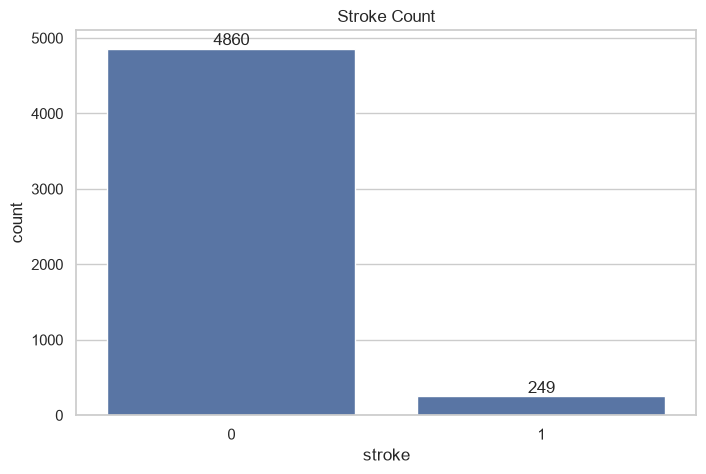

stroke
0    0.951
1    0.049
Name: proportion, dtype: float64


In [114]:
#0 for no stroke and 1 for stroke, we will plot the count of stroke and no stroke
ax=sns.countplot(data=data,x="stroke")   #creates a bar plot for the stroke column
ax.set_title("Stroke Count")   #sets the title of the plot
for p in ax.patches:         #(text,(x,y),alignment)
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.show()    
#show the percentage of stroke and no stroke
print(data["stroke"].value_counts(normalize=True).round(3))


<h2>Observation:</h2>Strokes are rare(abput 5%),so the data is heavily imbalanced.Accuracy alone will be misleading;we need recall,precision and ROC-AUC.

<h3>5.Univariate analysis</h3>  Study of a single variable before studying the relationships between variables.

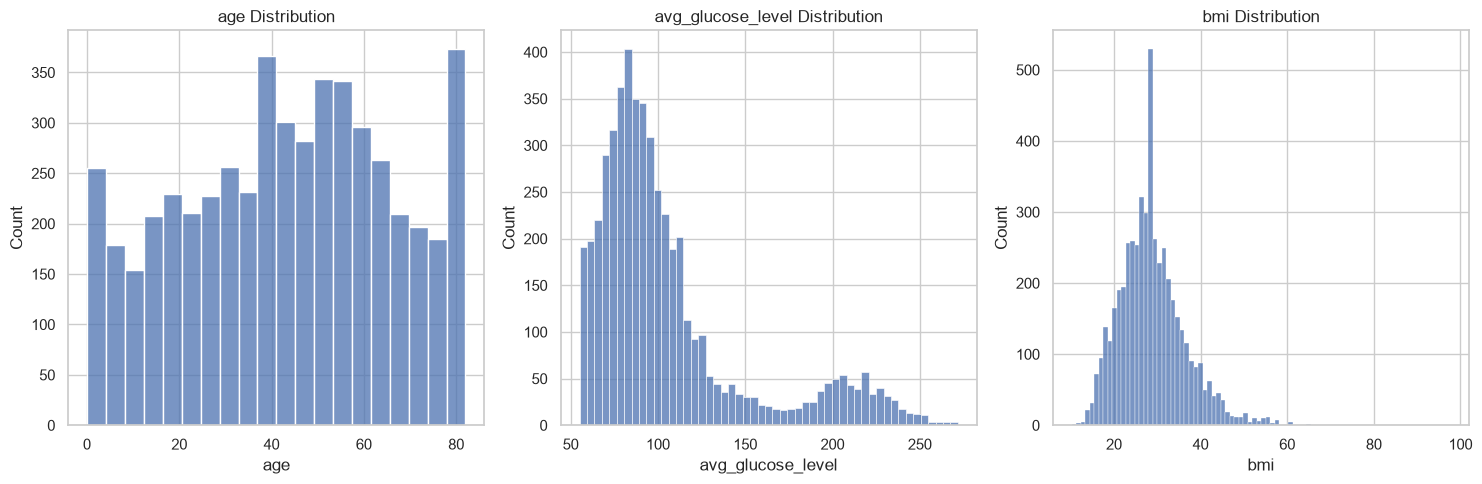

In [115]:
num_cols=["age","avg_glucose_level","bmi"]     #list of numeric variables we want to analyze
fig,axes=plt.subplots(1,3,figsize=(15,5))       #creates a figure with 1 row and 3 columns of subplots
for i,col in zip(axes,num_cols):      #iterates over the axes and numeric columns
    sns.histplot(data=data,x=col,ax=i)    #creates a histogram for each numeric column
    i.set_title(f"{col} Distribution")     #sets the title of each subplot
plt.tight_layout()                         #sets the layout of the subplots to avoid overlap
plt.show()      
       

<h3>6.Bivariate Analysis -Numeric features VS Stroke</h3>

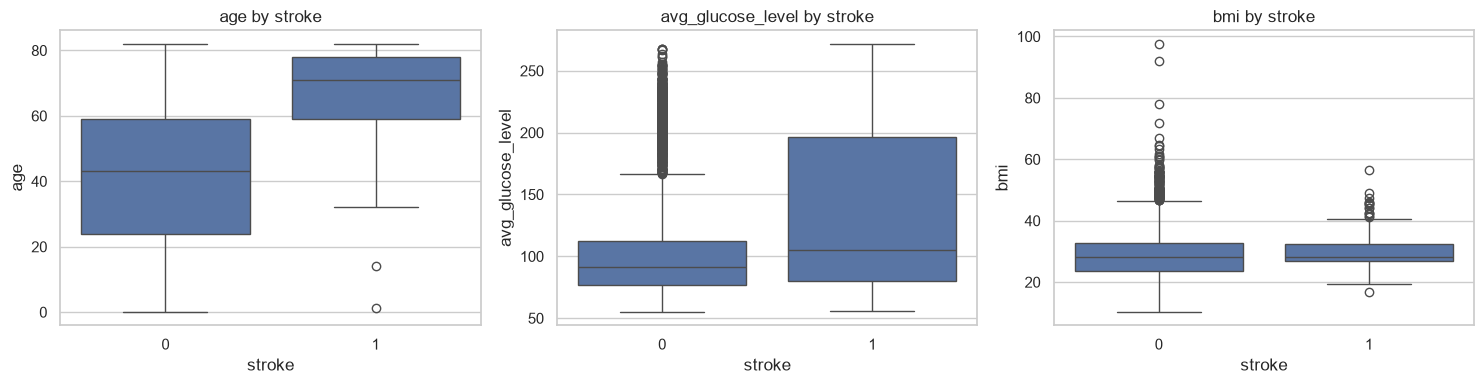

In [116]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=data, x="stroke", y=col, ax=ax)
    ax.set_title(f"{col} by stroke")
plt.tight_layout()
plt.show()

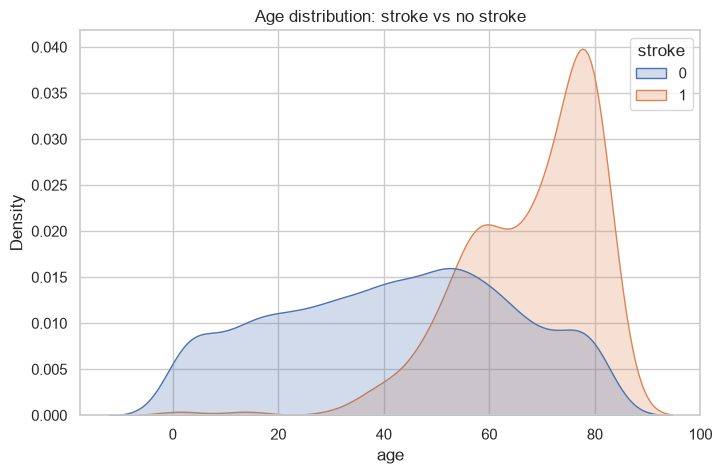

In [117]:
#Draw a Kernel Density Estimate (KDE) plot to visualize the distribution of age for stroke and no stroke
sns.kdeplot(data=data, x="age", hue="stroke", common_norm=False, fill=True)
plt.title("Age distribution: stroke vs no stroke")
plt.show()

<h3>7.Categorial features vs stroke rate</h3>

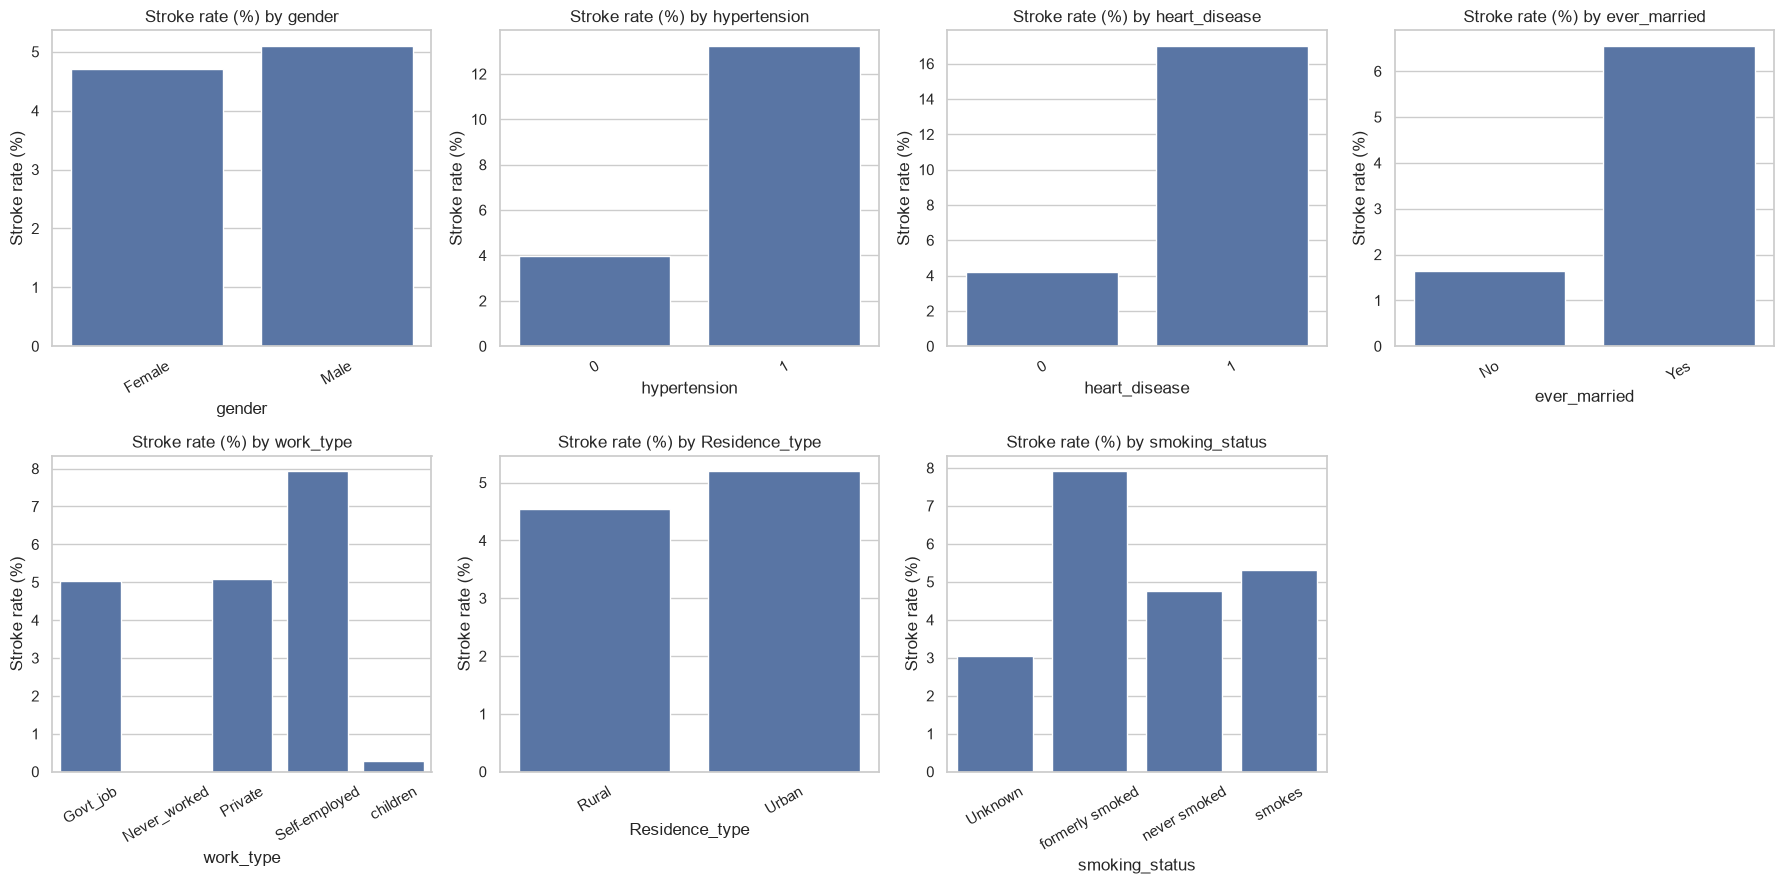

In [118]:
cat_cols = ["gender", "hypertension", "heart_disease", "ever_married",
            "work_type", "Residence_type", "smoking_status"]          #list of categorical values we want to analyze
fig, axes = plt.subplots(2, 4, figsize=(18, 9))                       #creates a grid of 2 rows and 4 columns(8 plots)
axes = axes.ravel()                                                #flattens the 2D array of axes into a 1D array for easier looping
for ax, col in zip(axes, cat_cols):
    rate = data.groupby(col)["stroke"].mean() * 100                #calculates stroke rate for each category in the categorical column
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)    #draws a bar chart for the stroke rate by category
    ax.set_title(f"Stroke rate (%) by {col}")
    ax.set_ylabel("Stroke rate (%)")
    ax.tick_params(axis="x",rotation=30)
axes[-1].axis("off")                                               #we have 8 plots but only 7 categorical columns, so we turn off the last axis
plt.tight_layout()
plt.show()

<h3> 8.Correlation Heatmap </h3>


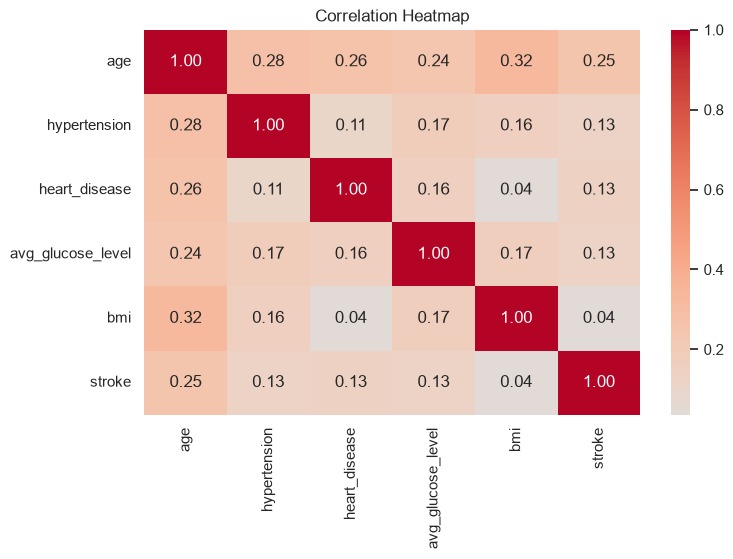

In [119]:
corr= data.select_dtypes(include="number").corr()  #calculates the correlation matrix for numeric columns
sns.heatmap(corr,annot=True, fmt=".2f", cmap="coolwarm",center=0)  #creates a heatmap of the correlation matrix with annotations
plt.title("Correlation Heatmap")  #sets the title of the heatmap
plt.show()

<h3>9.Age groups and glucose levels</h3>

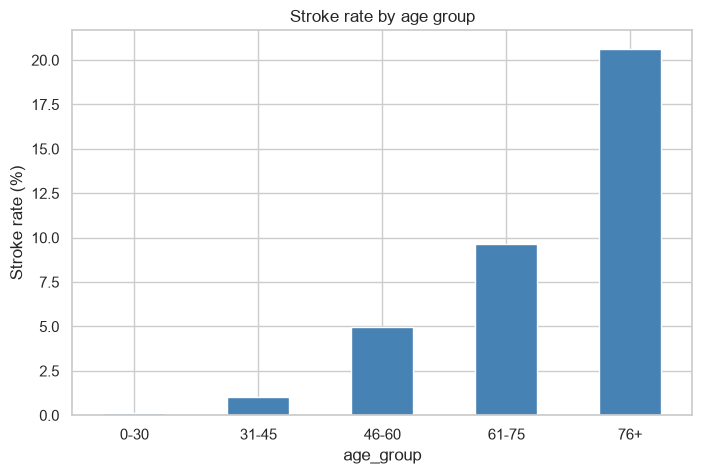

In [120]:
#For Age Group Analysis, we will create a new column "age_group" by binning the "age" column into 5 age groups: 0-30, 31-45, 46-60, 61-75, and 76+. We will then calculate the stroke rate for each age group and create a bar plot to visualize the stroke rate by age group.
data["age_group"] = pd.cut(data["age"], bins=[0, 30, 45, 60, 75, 100],
                         labels=["0-30", "31-45", "46-60", "61-75", "76+"])   #creates a new column "age_group" by binning the "age" column into 5 age groups
rate = data.groupby("age_group", observed=True)["stroke"].mean() * 100        #calculates the stroke rate for each age group
rate.plot(kind="bar", color="steelblue")                                      #creates a bar plot for the stroke rate by age group
plt.ylabel("Stroke rate (%)")
plt.title("Stroke rate by age group")
plt.xticks(rotation=0)                                                        #keeps the x-axis labels horizontal
plt.show()

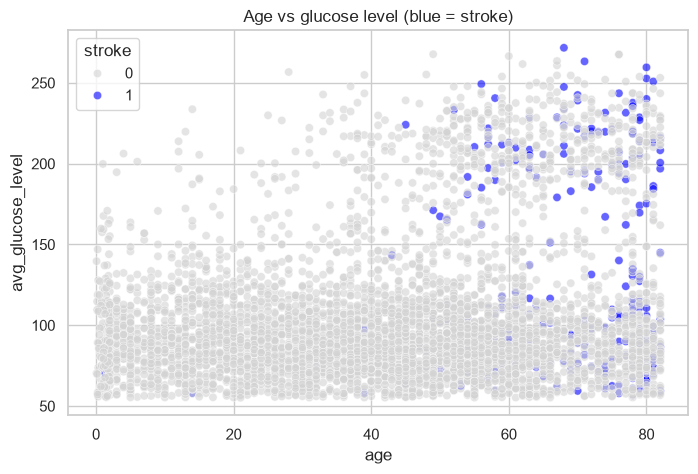

In [121]:
#For Glucose Level Analysis, we will create a scatter plot to visualize the relationship between age and average glucose level, with stroke status indicated by color. This will help us understand if there is any correlation between these variables and stroke occurrence.
sns.scatterplot(data=data, x="age", y="avg_glucose_level", hue="stroke",
                alpha=0.6, palette={0: "lightgrey", 1: "blue"})
plt.title("Age vs glucose level (blue = stroke)")
plt.show()

<h3>10.Preparing Data for Modelling</h3>

In [123]:
model_df = data.drop(columns="age_group")
model_df = pd.get_dummies(model_df, drop_first=True)

X = model_df.drop(columns="stroke")
y = model_df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(4087, 15) (1022, 15)


<h3>11.Models</h3>

In [124]:
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000)
log_reg.fit(X_train_s, y_train)

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

<h3>12.Evaluation</h3>

In [127]:
results = {
    "Logistic Regression": (log_reg, X_test_s),
    "Random Forest": (rf, X_test),
}

for name, (model, Xt) in results.items():
    pred = model.predict(Xt)
    proba = model.predict_proba(Xt)[:, 1]
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, digits=3))
    print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\n")

===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.986     0.736     0.843       972
           1      0.135     0.800     0.231        50

    accuracy                          0.739      1022
   macro avg      0.560     0.768     0.537      1022
weighted avg      0.945     0.739     0.813      1022

ROC-AUC: 0.84 

===== Random Forest =====
              precision    recall  f1-score   support

           0      0.984     0.841     0.907       972
           1      0.193     0.740     0.306        50

    accuracy                          0.836      1022
   macro avg      0.589     0.790     0.606      1022
weighted avg      0.946     0.836     0.877      1022

ROC-AUC: 0.818 



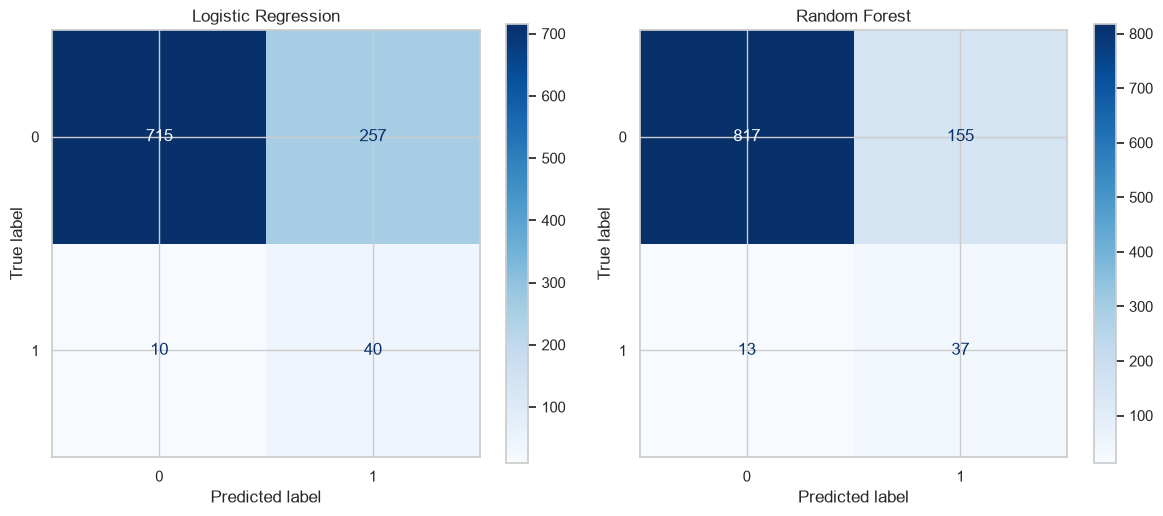

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (model, Xt)) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(Xt), ax=ax, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

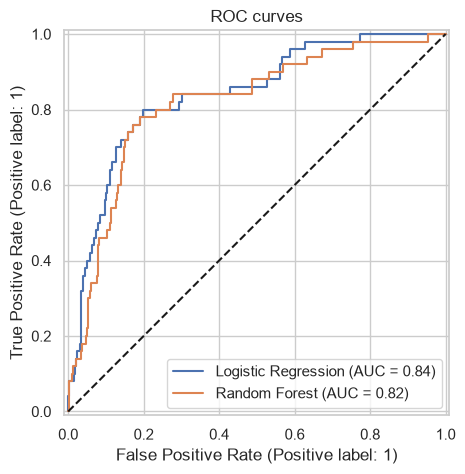

In [129]:
fig, ax = plt.subplots()
for name, (model, Xt) in results.items():
    RocCurveDisplay.from_estimator(model, Xt, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("ROC curves")
plt.show()

<h3>13.Feature importance</h3>

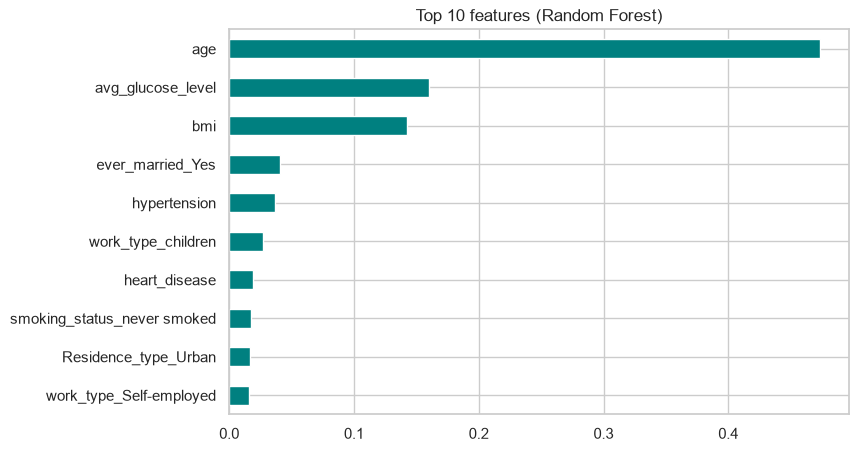

In [130]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 features (Random Forest)")
plt.show()

<h3>14.Conclusion</h3>
- Age is the dominant risk factor, with stroke rare below 40, rising steeply after 60, and highest in people aged 75 and over.<br>
- Hypertension, heart disease, and high glucose levels are strongly associated with stroke, with about three times higher risk compared to those without.<br>
-Gender, residence type, and BMI show little or no relationship with stroke<br>
-Marital status, work type, and smoking status appear important but are largely explained by age, since older groups inflate stroke rates.
- The dataset is heavily imbalanced, so recall and ROC-AUC matter more than accuracy.<br>
- Limitations: few stroke cases, median-imputed BMI, no causal claims.<br>
-Next steps: Try oversampling (e.g. SMOTE), tune hyperparameters, use cross-validation, and adjust the decision threshold to balance recall and precision.